# DSC212: Graph Theory — Modularity on the Karate Club Graph

**Research assignment project**

This notebook implements recursive spectral modularity partitioning on Zachary's Karate Club graph, visualizes each partition, computes four node metrics after each split, and plots how those metrics evolve.

## Method used
- Build the **global modularity matrix**: \(B=A-kk^T/(2m)\).
- For each candidate community \(C\), use the principal submatrix \(B^{(C)}\) from the original global matrix, as specified in the assignment handout.
- Find its largest eigenvalue/eigenvector using `numpy.linalg.eigh`.
- Split by the signs of the leading eigenvector when the leading eigenvalue is positive.
- Stop a branch when its leading eigenvalue is nonpositive, a valid bipartition cannot be formed, or the sign-based split does not have positive modularity gain.
- Compute node metrics **inside each node's current community-induced subgraph**. This makes the reported metrics reflect the changing community structure; this choice is explained in the discussion.

> Run the notebook from top to bottom. No manual edits or external data files are required.

## 1. Import libraries

The notebook uses NetworkX's built-in Karate Club graph, so no separate dataset download is needed.

In [1]:
import os
import math
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
OUTPUT_DIR = "visualizations"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("NetworkX version:", nx.__version__)
print("NumPy version:", np.__version__)

NetworkX version: 3.6.1
NumPy version: 2.3.5


## 2. Load and inspect the Karate Club graph

The benchmark graph contains 34 members (nodes) and 78 friendship links (edges). The `club` node attribute records the observed faction labels from the original dataset; it is shown only for context and is **not used** by the community-detection algorithm.

Number of nodes: 34
Number of edges: 78
Observed faction labels (context only): ['Mr. Hi', 'Officer']


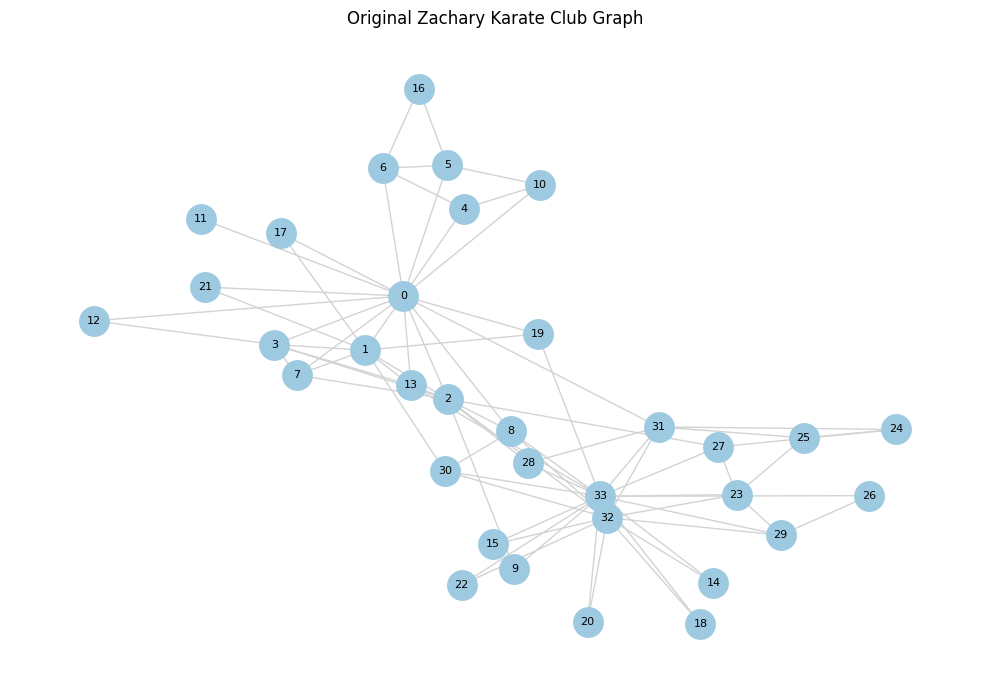

In [2]:
G = nx.karate_club_graph()
nodes = list(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

print(f"Number of nodes: {n}")
print(f"Number of edges: {m}")
print("Observed faction labels (context only):", sorted(set(nx.get_node_attributes(G, "club").values())))

pos = nx.spring_layout(G, seed=SEED)
plt.figure(figsize=(10, 7))
nx.draw_networkx(G, pos=pos, node_size=450, font_size=8, edge_color="lightgray",
                 node_color="#9ecae1", with_labels=True)
plt.title("Original Zachary Karate Club Graph")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "01_original_graph.png"), dpi=180, bbox_inches="tight")
plt.show()

## 3. Construct the global modularity matrix

For an undirected graph with adjacency matrix \(A\), degree vector \(k\), and \(m\) edges:

\[
B=A-\frac{kk^T}{2m}.
\]

The assignment asks us to restrict this **original global matrix** to each candidate community when recursively testing it.

In [3]:
A = nx.to_numpy_array(G, nodelist=nodes, dtype=float)
degree_vector = A.sum(axis=1)
B = A - np.outer(degree_vector, degree_vector) / (2 * m)

print("Adjacency matrix shape:", A.shape)
print("Modularity matrix shape:", B.shape)
print("Symmetric:", np.allclose(B, B.T))
print("Maximum absolute row sum (approximately 0):", np.max(np.abs(B.sum(axis=1))))

Adjacency matrix shape: (34, 34)
Modularity matrix shape: (34, 34)
Symmetric: True
Maximum absolute row sum (approximately 0): 94.15384615384616


## 4. Spectral split and recursive partitioning

For each candidate community:
1. Extract the principal submatrix of the global modularity matrix.
2. Compute its largest eigenvalue and corresponding eigenvector.
3. If the largest eigenvalue is positive, assign nodes by the sign of the eigenvector.
4. Calculate the sign-split modularity gain \(\Delta Q=s^TB^{(C)}s/(4m)\).
5. Recurse on both groups if the split is non-empty and has positive gain.

The eigenvalue test is the assignment's stopping rule. The additional non-empty/positive-gain checks protect against degenerate numerical sign splits.

In [4]:
def restricted_modularity_matrix(community):
    """Return the principal block of the original global modularity matrix."""
    idx = [nodes.index(v) for v in community]
    return B[np.ix_(idx, idx)]


def spectral_split(community):
    """Try one spectral split. Return details, or a reason why it cannot split."""
    community = list(community)
    if len(community) < 2:
        return None, {"reason": "Community has fewer than two nodes."}

    Bc = restricted_modularity_matrix(community)
    eigenvalues, eigenvectors = np.linalg.eigh(Bc)  # symmetric matrix
    leading_index = int(np.argmax(eigenvalues))
    leading_value = float(eigenvalues[leading_index])
    leading_vector = eigenvectors[:, leading_index]

    if leading_value <= 1e-10:
        return None, {"reason": "Largest eigenvalue is nonpositive.", "lambda_max": leading_value}

    positive = [v for v, x in zip(community, leading_vector) if x > 0]
    nonpositive = [v for v, x in zip(community, leading_vector) if x <= 0]

    if not positive or not nonpositive:
        return None, {"reason": "Eigenvector signs did not produce two non-empty groups.",
                      "lambda_max": leading_value}

    s = np.array([1.0 if x > 0 else -1.0 for x in leading_vector])
    delta_q = float(s @ Bc @ s / (4 * m))

    if delta_q <= 1e-12:
        return None, {"reason": "Sign-based split has no positive modularity gain.",
                      "lambda_max": leading_value, "delta_q": delta_q}

    return (positive, nonpositive), {
        "lambda_max": leading_value,
        "delta_q": delta_q,
        "group_sizes": (len(positive), len(nonpositive))
    }


# Each state stores the complete partition after a successful split.
initial_partition = [nodes.copy()]
partition_history = [initial_partition]
split_log = []

def recurse_partition(community, depth=0):
    split, info = spectral_split(community)
    if split is None:
        split_log.append({
            "depth": depth,
            "community_nodes": list(community),
            "split": False,
            **info
        })
        return [list(community)]

    left, right = split
    split_log.append({
        "depth": depth,
        "community_nodes": list(community),
        "split": True,
        **info
    })

    # Save the full partition after this successful split.
    # The current recursion branch is replaced by its two children.
    result_left = recurse_partition(left, depth + 1)
    result_right = recurse_partition(right, depth + 1)
    return result_left + result_right


final_communities = recurse_partition(nodes)
# Reconstruct a readable sequence of global partitions by replaying successful splits.
partitions = [initial_partition]
current = [nodes.copy()]
for entry in split_log:
    if entry["split"]:
        target = set(entry["community_nodes"])
        # Find the current community that matches the split target.
        match_index = next((i for i, c in enumerate(current) if set(c) == target), None)
        if match_index is not None:
            split, _ = spectral_split(current[match_index])
            if split is not None:
                current = current[:match_index] + [split[0], split[1]] + current[match_index+1:]
                partitions.append([list(c) for c in current])

# Remove any duplicate partition snapshots while preserving order.
unique_partitions = []
seen = set()
for part in partitions:
    key = tuple(sorted(tuple(sorted(c)) for c in part))
    if key not in seen:
        seen.add(key)
        unique_partitions.append(part)
partitions = unique_partitions

print("Successful recursive splits:", len(partitions) - 1)
print("Final number of communities:", len(final_communities))
print("Final community sizes:", sorted([len(c) for c in final_communities], reverse=True))
display(pd.DataFrame(split_log)[["depth", "split", "lambda_max", "delta_q", "reason"]]
        if split_log else pd.DataFrame())

Successful recursive splits: 5
Final number of communities: 6
Final community sizes: [12, 8, 5, 4, 3, 2]


,depth,split,lambda_max,delta_q,reason
0,0,True,17.108349,1.188774,NaN
1,1,True,7.879863,0.246795,NaN
2,2,False,3.789452,-0.030161,Sign-based split has no positive modularity gain.
3,2,True,4.224803,0.053665,NaN
4,3,False,3.865803,NaN,Eigenvector signs did not produce two non-empt...
5,3,False,0.457863,NaN,Eigenvector signs did not produce two non-empt...
6,1,True,9.851071,0.325855,NaN
7,2,False,2.112386,-0.026648,Sign-based split has no positive modularity gain.
8,2,True,5.457362,0.083313,NaN
9,3,False,0.426857,NaN,Eigenvector signs did not produce two non-empt...


## 5. Visualize the graph after every split

A single spring layout is reused for every figure so that node positions stay fixed and community changes are easy to compare.

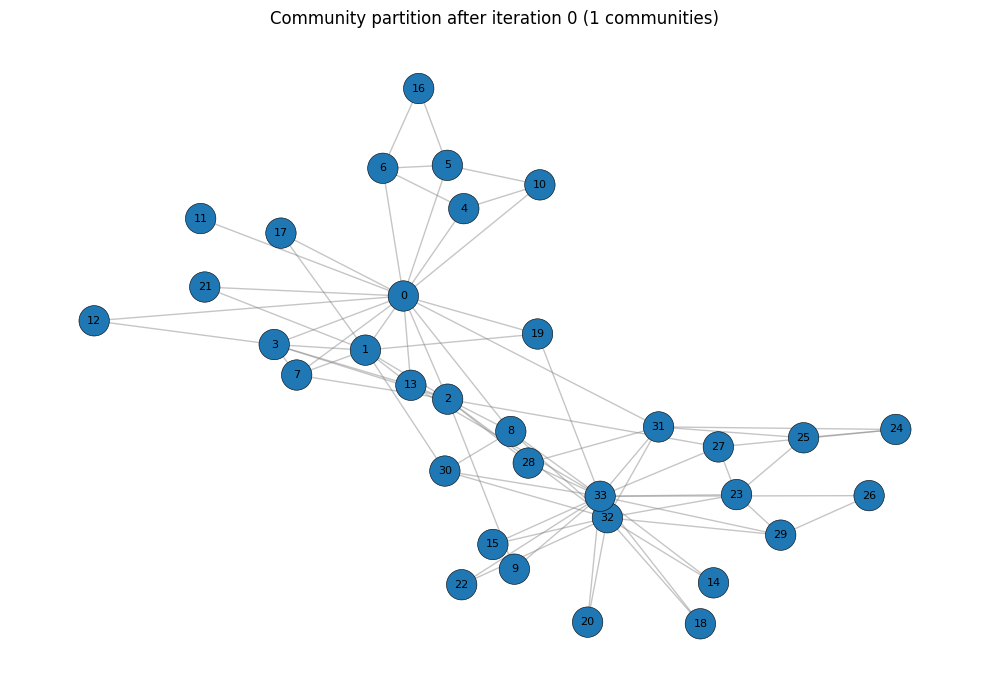

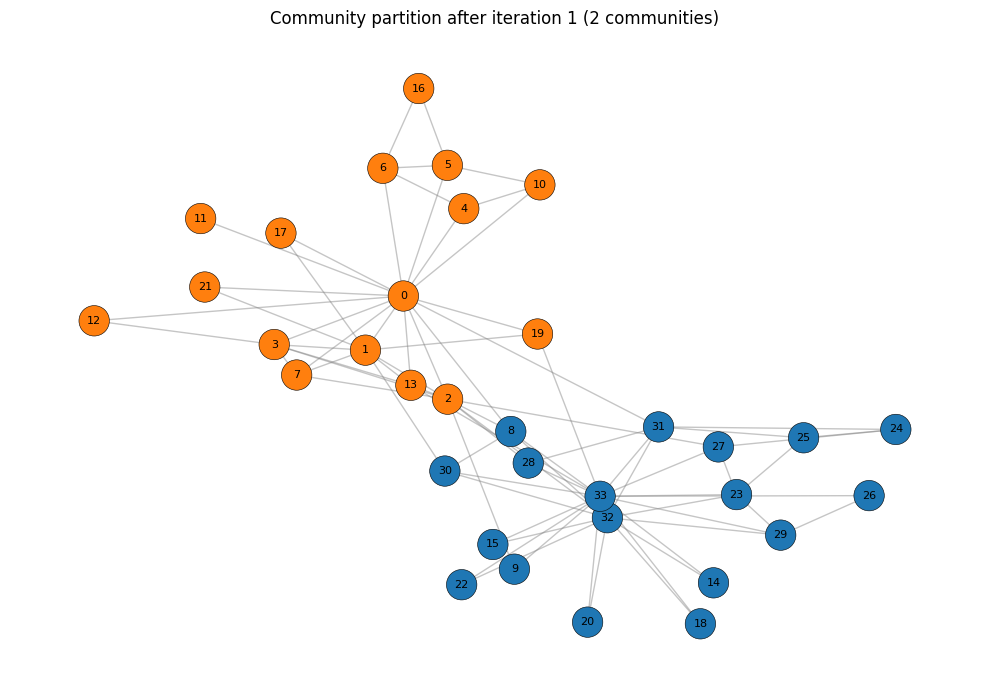

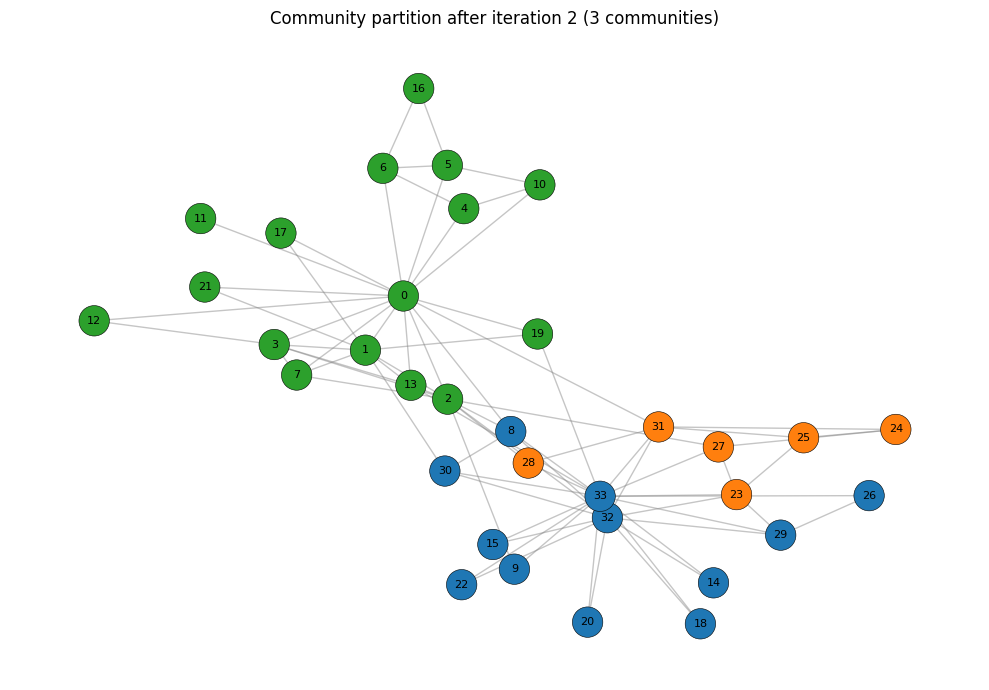

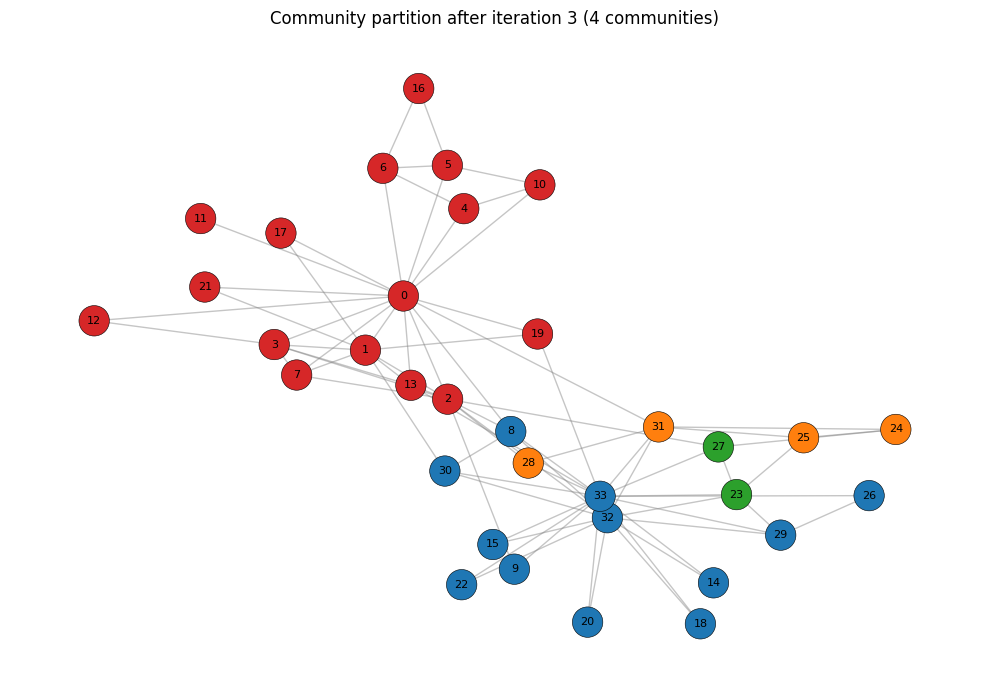

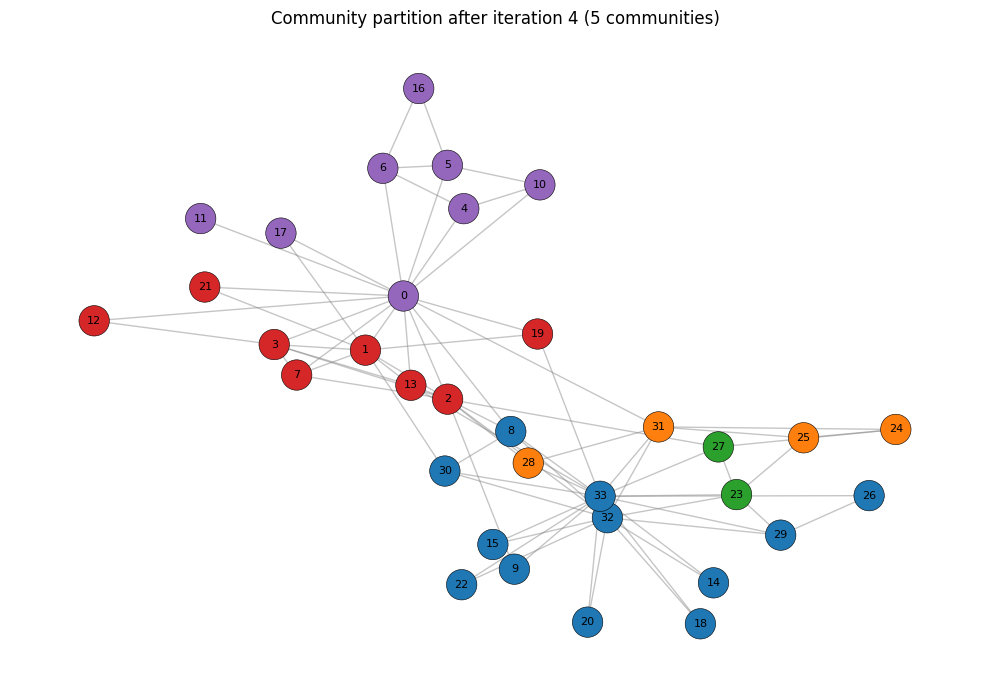

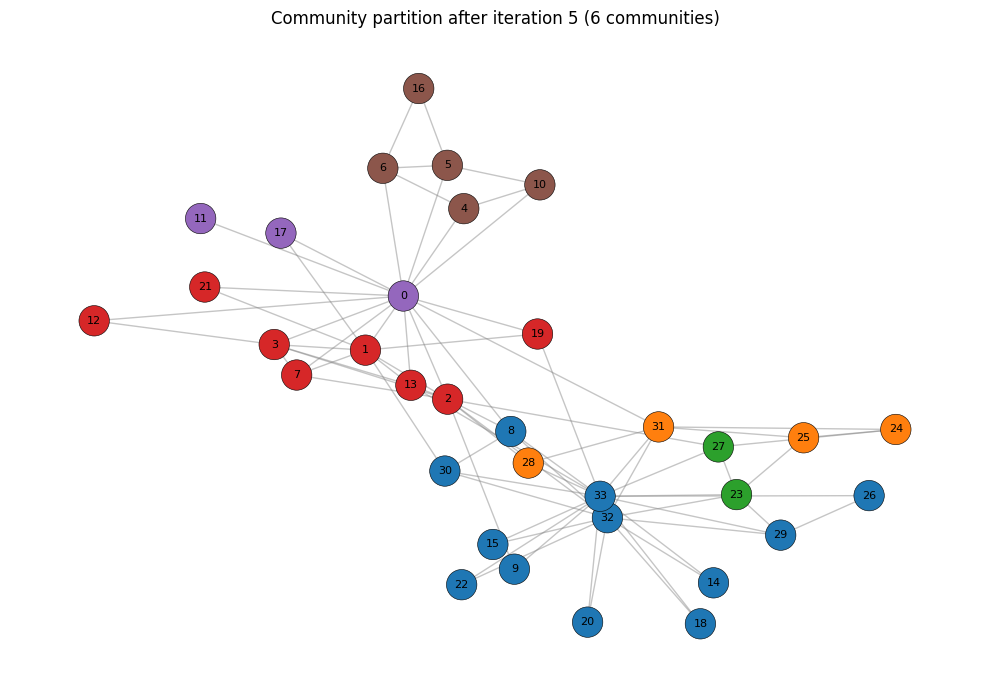

Saved 6 partition visualizations in 'visualizations'.


In [5]:
def draw_partition(graph, partition, iteration, save=True):
    node_to_community = {}
    for cid, community in enumerate(partition):
        for node in community:
            node_to_community[node] = cid

    cmap = plt.get_cmap("tab10")
    colors = [cmap(node_to_community[node] % 10) for node in graph.nodes()]

    plt.figure(figsize=(10, 7))
    nx.draw_networkx_edges(graph, pos, alpha=0.45, edge_color="gray")
    nx.draw_networkx_nodes(graph, pos, node_color=colors, node_size=480,
                           edgecolors="black", linewidths=0.4)
    nx.draw_networkx_labels(graph, pos, font_size=8)
    plt.title(f"Community partition after iteration {iteration} ({len(partition)} communities)")
    plt.axis("off")
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(OUTPUT_DIR, f"02_partition_iteration_{iteration}.png"),
                    dpi=180, bbox_inches="tight")
    plt.show()


for iteration, partition in enumerate(partitions):
    draw_partition(G, partition, iteration)

print(f"Saved {len(partitions)} partition visualizations in '{OUTPUT_DIR}'.")

## 6. Compute node metrics after each split

For each snapshot, each node's four metrics are calculated on the induced subgraph of the community to which that node currently belongs:

- Degree centrality
- Betweenness centrality
- Closeness centrality
- Clustering coefficient

This is a community-level view of node position. Nodes are always included in exactly one community. A singleton community receives zero for all four measures.

In [6]:
METRICS = ["degree_centrality", "betweenness_centrality",
           "closeness_centrality", "clustering"]

def calculate_metrics_for_partition(graph, partition, iteration):
    records = []
    for community_id, community in enumerate(partition):
        subgraph = graph.subgraph(community).copy()

        degree_values = nx.degree_centrality(subgraph)
        betweenness_values = nx.betweenness_centrality(subgraph, normalized=True)
        closeness_values = nx.closeness_centrality(subgraph)
        clustering_values = nx.clustering(subgraph)

        for node in community:
            records.append({
                "iteration": iteration,
                "node": node,
                "community": community_id,
                "degree_centrality": float(degree_values.get(node, 0.0)),
                "betweenness_centrality": float(betweenness_values.get(node, 0.0)),
                "closeness_centrality": float(closeness_values.get(node, 0.0)),
                "clustering": float(clustering_values.get(node, 0.0)),
            })
    return records


metric_records = []
for iteration, partition in enumerate(partitions):
    metric_records.extend(calculate_metrics_for_partition(G, partition, iteration))

metrics_df = pd.DataFrame(metric_records).sort_values(["iteration", "node"]).reset_index(drop=True)
print("Metric table shape:", metrics_df.shape)
display(metrics_df.head(15))

Metric table shape: (204, 7)


,iteration,node,community,degree_centrality,betweenness_centrality,closeness_centrality,clustering
0,0,0,0,0.484848,0.437635,0.568966,0.150000
1,0,1,0,0.272727,0.053937,0.485294,0.333333
2,0,2,0,0.303030,0.143657,0.559322,0.244444
3,0,3,0,0.181818,0.011909,0.464789,0.666667
4,0,4,0,0.090909,0.000631,0.379310,0.666667
5,0,5,0,0.121212,0.029987,0.383721,0.500000
6,0,6,0,0.121212,0.029987,0.383721,0.500000
7,0,7,0,0.121212,0.000000,0.440000,1.000000
8,0,8,0,0.151515,0.055927,0.515625,0.500000
9,0,9,0,0.060606,0.000848,0.434211,0.000000


## 7. Plot how the metrics evolve across iterations

Each line represents one node. The x-axis is the partition iteration; the y-axis is the metric value calculated within that node's current community.

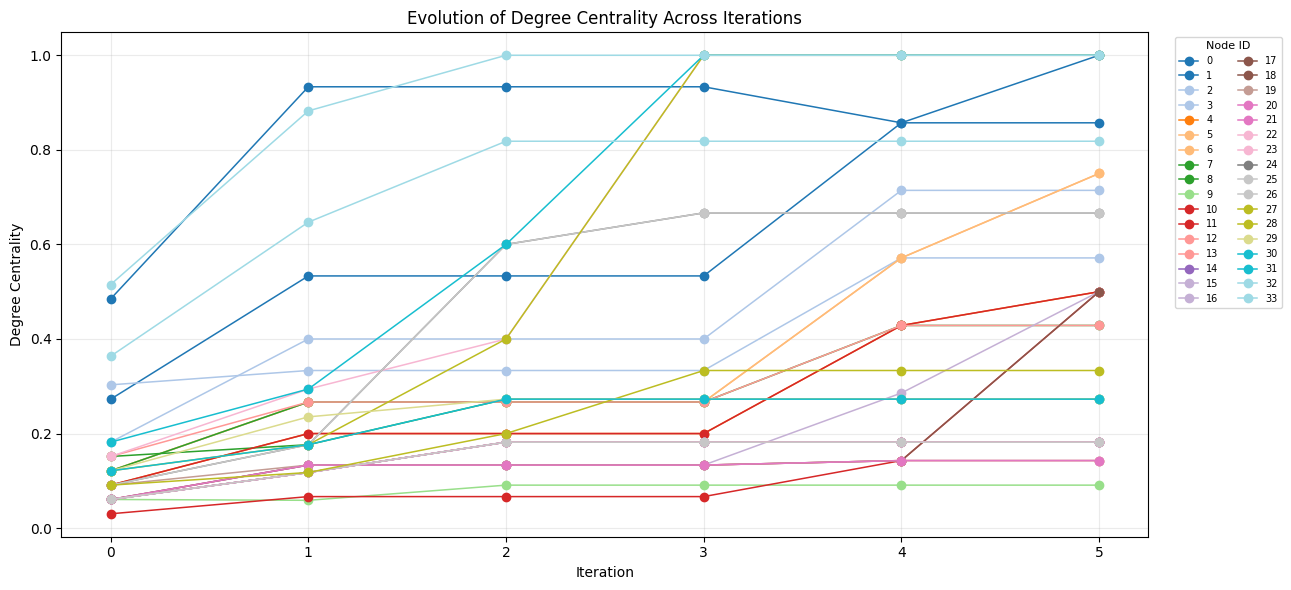

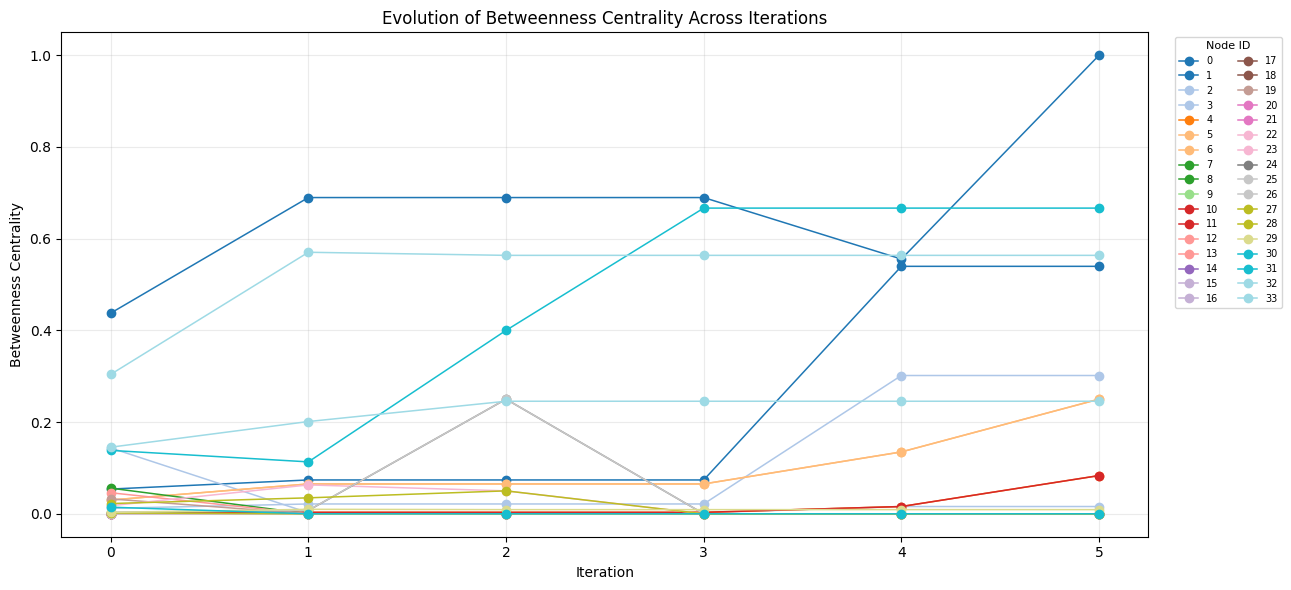

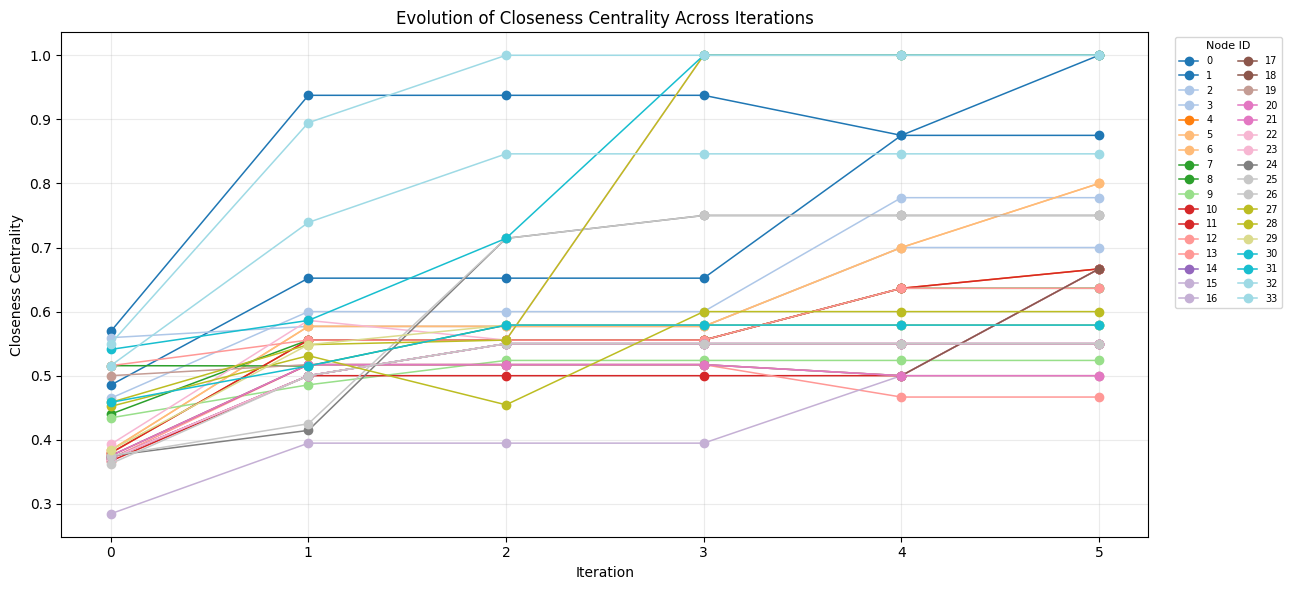

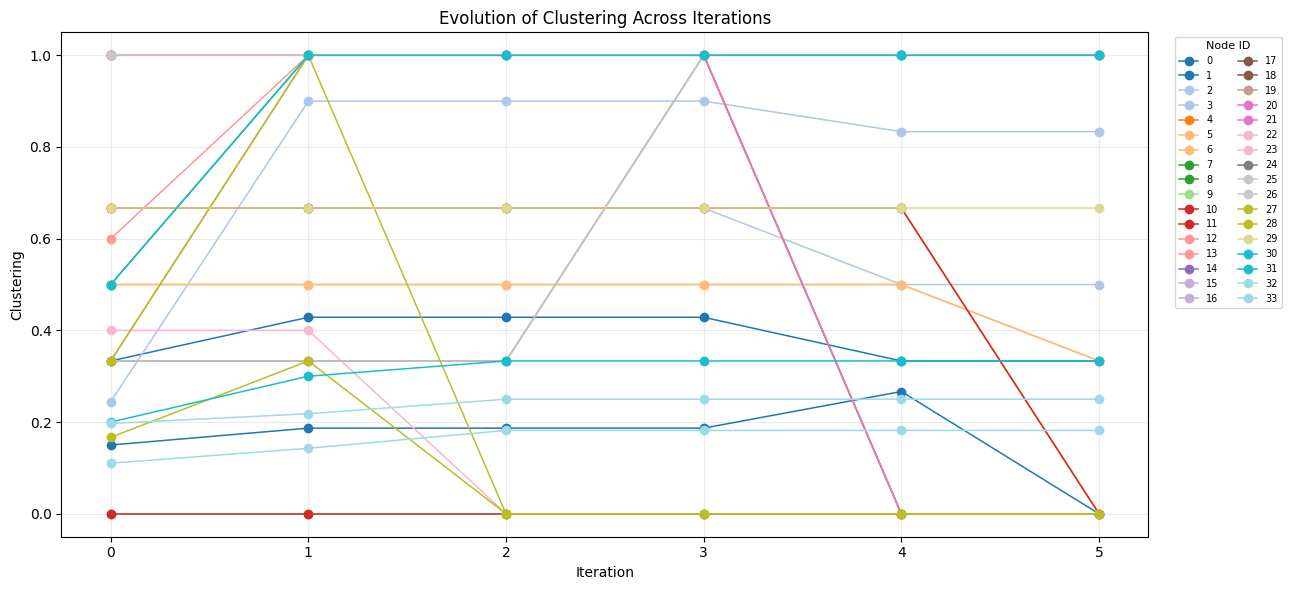

Saved four metric-evolution plots in: visualizations


In [7]:
for metric in METRICS:
    pivot = metrics_df.pivot(index="iteration", columns="node", values=metric)
    ax = pivot.plot(figsize=(13, 6), marker="o", linewidth=1.1, legend=False,
                    colormap="tab20")
    ax.set_title(f"Evolution of {metric.replace('_', ' ').title()} Across Iterations")
    ax.set_xlabel("Iteration")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.grid(True, alpha=0.25)
    ax.set_xticks(sorted(metrics_df["iteration"].unique()))
    # A compact legend is kept outside the plotting area.
    ax.legend(title="Node ID", bbox_to_anchor=(1.02, 1), loc="upper left",
              ncol=2, fontsize=7, title_fontsize=8)
    plt.tight_layout()
    filename = f"03_{metric}_evolution.png"
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=180, bbox_inches="tight")
    plt.show()

print("Saved four metric-evolution plots in:", OUTPUT_DIR)

## 8. Summary tables

The following table shows the final community membership. The second table gives the average metric values across all nodes at each iteration.

In [8]:
membership_rows = []
for community_id, community in enumerate(final_communities):
    for node in sorted(community):
        membership_rows.append({"node": node, "final_community": community_id})

membership_df = pd.DataFrame(membership_rows).sort_values("node").reset_index(drop=True)
display(membership_df)

average_metrics = metrics_df.groupby("iteration")[METRICS].mean().round(4)
display(average_metrics)

,node,final_community
0,0,4
1,1,3
2,2,3
3,3,3
4,4,5
5,5,5
6,6,5
7,7,3
8,8,0
9,9,0


,degree_centrality,betweenness_centrality,closeness_centrality,clustering
iteration,,,,
0,0.1390,0.0440,0.4265,0.5706
1,0.2505,0.0568,0.5558,0.6836
2,0.3241,0.0806,0.5948,0.6357
3,0.3790,0.0708,0.6357,0.6749
4,0.4512,0.0941,0.6661,0.5500
5,0.4975,0.1179,0.6921,0.4931


## 9. Discussion and interpretation

### Which nodes remain central?
Use the metric-evolution plots and the final summary table to identify nodes that repeatedly have comparatively high degree, betweenness, or closeness centrality. High degree indicates many direct links within the current community. High betweenness suggests a node lies on many shortest paths within that community. High closeness indicates short average distances to other members of that community.

### How does community structure influence the metrics?
When the graph is split into smaller induced subgraphs, edges connecting a node to members of other communities are no longer included in that node's local metric calculation. Consequently, degree centrality can decrease, betweenness can change substantially when bridge paths disappear, and closeness can change as the reachable subgraph becomes smaller. Clustering measures the fraction of a node's neighbors that are connected to one another, so it may rise or fall depending on the local structure retained inside the community.

### Important interpretation note
The metric plots in this notebook are **within-community metrics**, not metrics on the unchanged full graph. This is why they can evolve after a partition split. The assignment asks how community structure influences the metrics; calculating them on each induced community makes that effect visible. These values should not be directly confused with full-network centralities.

### Result-specific observations
After running the notebook, inspect the plots and fill in this paragraph with the node IDs that your computed results show to be consistently important:

> In the original graph, nodes ______ have comparatively high degree centrality, while nodes ______ act as important bridges according to betweenness centrality. As the network is divided into communities, the local centrality values change because inter-community links are excluded from each induced subgraph. Nodes that remain central within their own communities are ______. The clustering coefficient indicates that ______.

Do not leave the blanks in the final report: use the computed metric tables and plots to complete them.

## 10. Conclusion

This project implemented recursive spectral modularity partitioning on Zachary's Karate Club graph. It constructed the modularity matrix, used leading eigenvectors to propose community splits, applied a stopping condition to terminate recursion, visualized each partition, and tracked four node metrics within each community-induced subgraph. The results illustrate how spectral methods translate graph structure into community assignments and how local network position changes as communities are separated.

## 11. Reference

Newman, M. E. J. (2006). **Modularity and community structure in networks.** *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103

Assignment source: *DSC212: Graph Theory Module — Research Assignment: Modularity on the Karate Club Graph*.